# Data profile

Bronze as received. Each finding maps to a decision in code (last cell). Re-run: `make profile`.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.model_selection import GroupKFold, KFold, cross_val_score

from housing.config import load_settings
from housing.features import FEATURES, TARGET
from housing.model import RunSpec, build_model

df = pd.read_csv(load_settings("prod").bronze_path)
print(df.shape, "| nulls:", int(df.isna().sum().sum()), "| duplicates:", int(df.duplicated().sum()))

(16512, 9) | nulls: 0 | duplicates: 0


## Ranges and tails

In [2]:
df.describe(percentiles=[0.01, 0.5, 0.99]).T.round(2)

,count,mean,std,min,1%,50%,99%,max
MedInc,16512.0,3.80,1.87,0.50,1.05,3.48,10.48,15.00
HouseAge,16512.0,29.28,12.79,1.00,4.00,30.00,52.00,52.00
AveRooms,16512.0,5.39,2.66,0.85,2.54,5.16,10.56,141.91
AveBedrms,16512.0,1.10,0.51,0.38,0.87,1.05,2.21,34.07
Population,16512.0,1437.61,1160.66,3.00,93.11,1168.00,5839.89,35682.00
AveOccup,16512.0,3.01,5.13,0.69,1.53,2.83,5.40,599.71
Latitude,16512.0,35.25,2.09,32.54,32.67,34.10,40.29,41.95
Longitude,16512.0,-119.13,1.92,-124.35,-123.54,-118.30,-116.15,-114.31
MedHouseVal,16512.0,2.02,1.14,0.15,0.51,1.74,5.00,5.00


## Censoring

Target and `HouseAge` are capped at the source.

{'MedHouseVal': 'max 5.00001 on 4.4% of rows', 'HouseAge': 'max 52.0 on 7.0% of rows'}


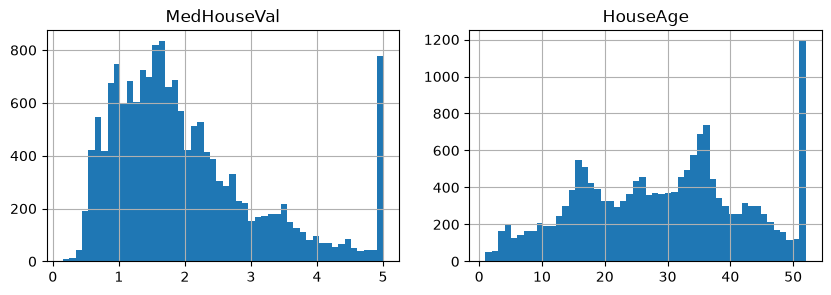

In [3]:
caps = {TARGET: df[TARGET].max(), "HouseAge": df["HouseAge"].max()}
print({c: f"max {v} on {(df[c] >= v).mean():.1%} of rows" for c, v in caps.items()})
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
for ax, col in zip(axes, caps):
    df[col].hist(bins=50, ax=ax)
    ax.set_title(col)
plt.show()

## Outliers

Ratios explode on a few block groups (dorms, resorts, institutions).

In [4]:
for col in ["AveRooms", "AveBedrms", "AveOccup", "Population"]:
    p99 = df[col].quantile(0.99)
    print(f"{col:<11} p99 {p99:>8.1f}  max {df[col].max():>9.1f}  rows > 3*p99: {(df[col] > 3 * p99).sum()}")

AveRooms    p99     10.6  max     141.9  rows > 3*p99: 22
AveBedrms   p99      2.2  max      34.1  rows > 3*p99: 20
AveOccup    p99      5.4  max     599.7  rows > 3*p99: 11
Population  p99   5839.9  max   35682.0  rows > 3*p99: 2


## Signal

In [5]:
df.corr()[TARGET].drop(TARGET).sort_values().round(2)

Latitude     -0.17
AveOccup     -0.05
AveBedrms    -0.04
Population   -0.03
Longitude     0.01
HouseAge      0.12
AveRooms      0.14
MedInc        0.67
Name: MedHouseVal, dtype: float64

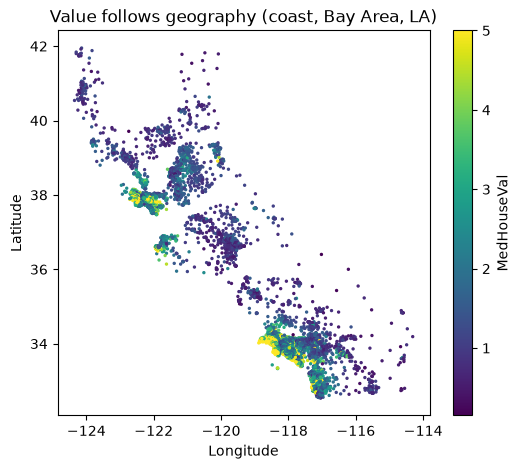

In [6]:
ax = df.plot.scatter("Longitude", "Latitude", c=TARGET, cmap="viridis", s=2, figsize=(6, 5))
ax.set_title("Value follows geography (coast, Bay Area, LA)")
plt.show()

## Split honesty

Neighbouring block groups are near-duplicates. Random folds vs folds that hold out whole 1° cells, same model as the champion.

In [7]:
model = build_model(RunSpec("gb", "gradient_boosting", engineered=True), seed=42)
cells = df["Latitude"].round().astype(str) + "_" + df["Longitude"].round().astype(str)
x, y = df[FEATURES], df[TARGET]
scores = {
    "random": -cross_val_score(model, x, y, cv=KFold(5, shuffle=True, random_state=42),
                               scoring="neg_root_mean_squared_error"),
    "spatial": -cross_val_score(model, x, y, cv=GroupKFold(5), groups=cells,
                                scoring="neg_root_mean_squared_error"),
}
pd.DataFrame(scores).agg(["mean", "std"]).round(3)

,random,spatial
mean,0.448,0.597
std,0.007,0.146


## Findings -> decisions

| Finding | Decision |
|---|---|
| No nulls, no duplicates | Silver still checks both: the next source may not be clean |
| Target capped at 5.00001 (4.4%) | Contract max = cap: an uncapped source fails Silver instead of mixing silently. Capped slice in metrics |
| `HouseAge` capped at 52 (7%) | Contract max 52: values above cannot exist in this encoding |
| Ratio outliers (`AveOccup` up to 600) | Kept: real block groups. Contract rejects impossible values only; tree models are robust |
| `MedInc` dominates (r 0.67); location is non-linear | Trees win; `MedInc` drift is the first alert to watch |
| Spatial CV RMSE ~0.60 vs ~0.45 random | Random split kept: it matches how hold-out rows are drawn. Spatial gap documented as the risk for unseen areas |
